# Settings

In [66]:
bf_data_path = "./data/csv/raw_beamformed/002_test1_angle1.npy"

# Imports

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json
from scipy import signal

# Import parameters

In [68]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [69]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  791
Upsampled samples:  3161
Step size:  1.6e-08 s
Maximal acquisition depth: 0.009492 m
Lateral step:  2.25e-05 m


# Load BF data

In [70]:
bf_matrices = np.load(bf_data_path)

# Display angles

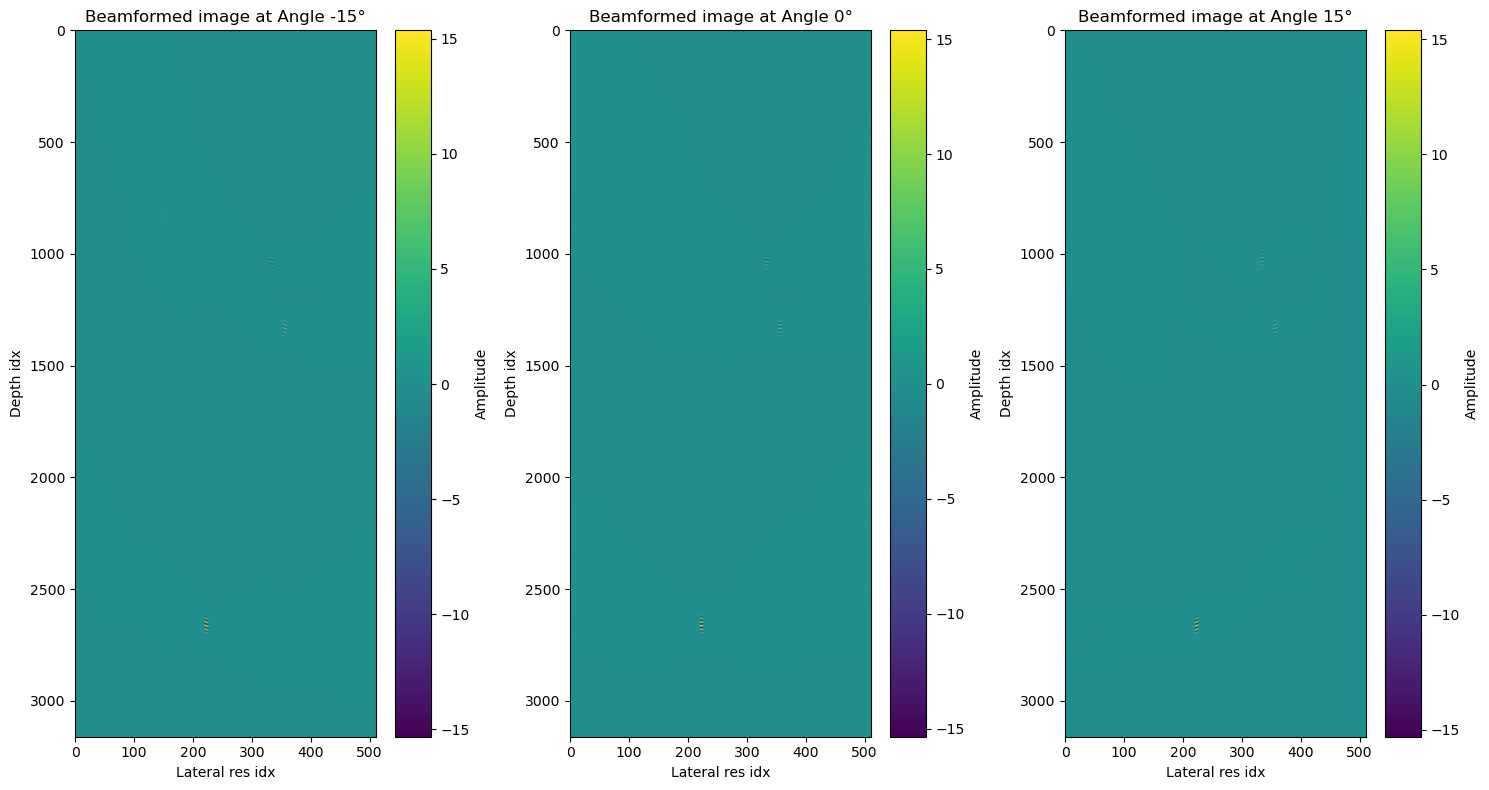

In [71]:

num_angles = len(params["wave"]["angles"])
fig, axes = plt.subplots(nrows=1, ncols=num_angles, figsize=(15,8))

if num_angles == 1:
    axes = [axes]

for i in range(num_angles):
    im = axes[i].imshow(bf_matrices[:,:,i], aspect='auto', cmap='viridis')
    axes[i].set_title(f'Beamformed image at Angle {params["wave"]["angles"][i]}°')
    axes[i].set_xlabel('Lateral res idx')
    axes[i].set_ylabel('Depth idx')
    fig.colorbar(im, ax=axes[i], label='Amplitude')

plt.tight_layout()
plt.show()

# Get most energy axial profile

In [72]:
def extract_highest_value_region(bf_matrix, submatrix_size=100):
    row, col = np.unravel_index(np.argmax(np.abs(bf_matrix)), bf_matrix.shape)
    
    half_size = int(submatrix_size/2)
    row_start = row - half_size if row - half_size >= 0 else 0
    row_end = row + half_size if row + half_size < bf_matrix.shape[0] else bf_matrix.shape[0]
    col_start = col - half_size if col - half_size >= 0 else 0
    col_end = col + half_size if col + half_size < bf_matrix.shape[1] else bf_matrix.shape[1]

    return bf_matrix[row_start:row_end, col_start:col_end]

## Images

Max value at angle -15°: 15.367617192010512
Max value row: 50, col: 50


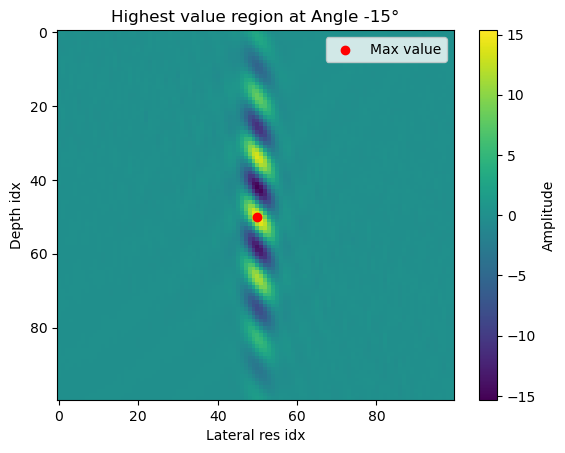

Max value at angle 0°: 15.38045485153446
Max value row: 50, col: 50


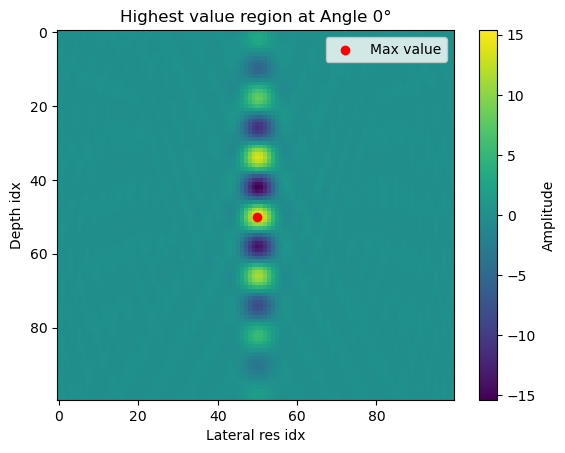

Max value at angle 15°: 15.380750954754124
Max value row: 50, col: 50


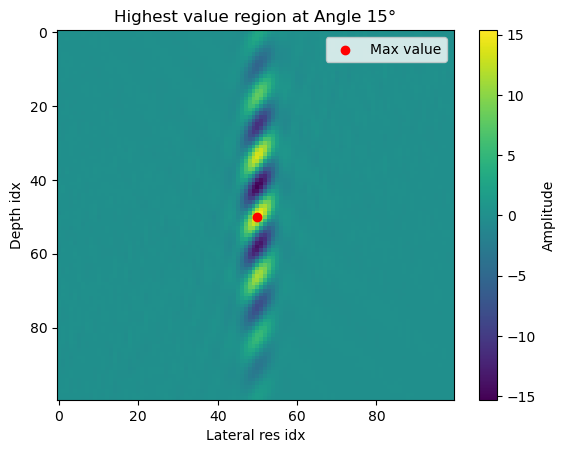

In [73]:
submatricies = []

for i in range(num_angles):
    submatrix = extract_highest_value_region(bf_matrices[:,:,i])
    submatricies.append(submatrix)
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatricies[i])), submatricies[i].shape)
    print(f"Max value at angle {params['wave']['angles'][i]}°: {submatricies[i][max_val_row, max_val_col]}")
    print(f"Max value row: {max_val_row}, col: {max_val_col}")
    plt.imshow(submatricies[i], aspect='auto', cmap='viridis')
    plt.title(f'Highest value region at Angle {params["wave"]["angles"][i]}°')
    plt.xlabel('Lateral res idx')
    plt.ylabel('Depth idx')
    plt.colorbar(label='Amplitude')
    plt.scatter(max_val_col, max_val_row, color='red', label='Max value')
    plt.legend()
    plt.show()

## Curves

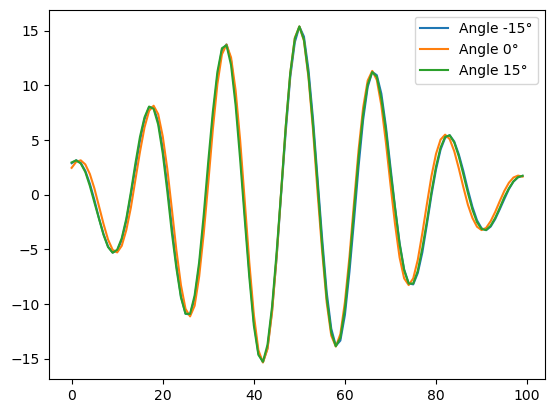

In [74]:
for i in range(len(submatricies)):
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatricies[i])), submatricies[i].shape)
    plt.plot(submatricies[i][:,max_val_col], label=f'Angle {params["wave"]["angles"][i]}°')
    plt.legend()